# 04 — Baseline Models

Before training ensembles we need reference points. A complex model is only useful if it clearly beats simple ones.

| Baseline | Idea | Why it is included |
|---|---|---|
| **Naive: last month** | Predict this month's bill = last month's bill | The persistence forecast — notebook 02 showed bills are very stable (r ≈ 0.93) |
| **Naive: mean of last 3 months** | Average of the last three bills | A smoother persistence forecast |
| **DummyRegressor** | Always predict the training mean | The "no information" floor |
| **Linear Regression** | Weighted sum of the features (least squares) | Simplest learned model |
| **Ridge Regression** | Linear regression with an L2 penalty on large coefficients | Handles strongly correlated lag features (lag_1, roll_mean_3, hist_mean…) |

**Same setup for every model:** history-only features, training Jan 2023 – May 2024, model selection by the mean
validation MAE over the 5 expanding one-month-ahead folds (Jan–May 2024), and the untouched test period Jun–Oct 2024
predicted one month ahead. **Errors are in kWh per household per month.**

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import plot_style as ps
from src.data_loader import CONSUMPTION_UNIT as U
from src.models import make_pipeline, MODEL_INFO
from src.train import load_modelling_data, run_model, load_summaries, load_test_predictions, load_cv
from src.evaluate import regression_metrics, per_month_metrics
ps.apply(); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
F, train, test = load_modelling_data()
print(f"Training rows: {len(train):,} ({train.month.min():%Y-%m}…{train.month.max():%Y-%m}) | "
      f"test rows: {len(test):,} ({test.month.min():%Y-%m}…{test.month.max():%Y-%m}) | unit: {U}")

Training rows: 68,485 (2023-01…2024-05) | test rows: 20,094 (2024-06…2024-10) | unit: kWh


## 1. Choosing Ridge's penalty strength (alpha) — validation folds only

`alpha` controls how strongly large coefficients are penalised. It is selected with the validation folds, never the
test set. A log-transformed target (`log(1 + kWh)`, predictions converted back to kWh) is also tried, because the
target is strongly right-skewed (notebook 02).

In [2]:
from src.evaluate import cross_validate_time
rows = []
for log_t in [False, True]:
    for a in [0.01, 1, 100, 1000, 3000, 10000, 30000]:
        cv, _ = cross_validate_time(make_pipeline("ridge", params={"alpha": a}, log_target=log_t), train, "history_only")
        rows.append({"target": "log(1+kWh)" if log_t else "kWh", "alpha": a, "cv_MAE": cv.val_MAE.mean(),
                     "cv_RMSE": cv.val_RMSE.mean(), "cv_R2": cv.val_R2.mean()})
alpha_table = pd.DataFrame(rows)
best = alpha_table.loc[alpha_table.cv_MAE.idxmin()]
print(f"Best by validation MAE: target={best.target}, alpha={best.alpha}")
alpha_table.round(3)

Best by validation MAE: target=kWh, alpha=1000.0


,target,alpha,cv_MAE,cv_RMSE,cv_R2
0,kWh,0.01,20.910,44.871,0.880
1,kWh,1.00,20.909,44.871,0.880
2,kWh,100.00,20.841,44.881,0.879
3,kWh,1000.00,20.806,45.014,0.879
4,kWh,3000.00,20.962,45.134,0.878
5,kWh,10000.00,21.297,45.336,0.877
6,kWh,30000.00,22.067,46.126,0.873
7,log(1+kWh),0.01,2574.422,149069.478,-2106632.805
8,log(1+kWh),1.00,2574.411,149069.455,-2106551.576
9,log(1+kWh),100.00,2584.252,149810.519,-2132343.646


**Observation.** For the kWh target, validation MAE changes very little with alpha (20.91 → 20.81 kWh); the best value
is **alpha = 1000**, with errors rising again for larger values — a genuine optimum inside the grid, not at its edge.

**Negative result — log target with a linear model.** The log-target Ridge produced absurd errors (MAE in the thousands
of kWh). This is expected once you see why: the model predicts log(kWh) as a *linear* function of *untransformed* bills,
so converting back with exp() makes the prediction an exponential of last month's bill — a household with a large bill
gets an astronomically large prediction. A log target only makes sense for a linear model if the inputs are also logged.
It is therefore not used for linear baselines; it is tested for tree ensembles in notebook 06, which cannot extrapolate this
way.

## 2. Run all baselines

In [3]:
best_alpha = float(alpha_table[alpha_table.target == "kWh"].sort_values("cv_MAE").iloc[0].alpha)
best_alpha_log = float(alpha_table[alpha_table.target != "kWh"].sort_values("cv_MAE").iloc[0].alpha)
baselines = {
    "naive_last_month": (make_pipeline("naive_last_month"), "naive_last_month"),
    "naive_mean_3m":    (make_pipeline("naive_mean_3m"), "naive_mean_3m"),
    "dummy_mean":       (make_pipeline("dummy_mean"), "dummy_mean"),
    "linear":           (make_pipeline("linear"), "linear"),
    "ridge":            (make_pipeline("ridge", params={"alpha": best_alpha}), "ridge"),
}
results, fitted = [], {}
for key, (model, label) in baselines.items():
    model_key = "ridge" if key.startswith("ridge") else key
    s, cv, preds, fm = run_model(model_key, model, experiment="main", label=label)
    results.append(s); fitted[label] = fm
res = pd.DataFrame(results).set_index("label")
cols = ["model", "cv_MAE", "cv_MAE_std", "cv_RMSE", "cv_R2", "test_MAE", "test_RMSE", "test_R2", "train_MAE", "fit_seconds_full"]
res[cols].sort_values("cv_MAE").round(3)

,model,cv_MAE,cv_MAE_std,cv_RMSE,cv_R2,test_MAE,test_RMSE,test_R2,train_MAE,fit_seconds_full
label,,,,,,,,,,
naive_last_month,Naive: last month's bill,19.695,2.484,47.836,0.861,19.491,48.843,0.861,18.969,0.001
ridge,Ridge Regression,20.806,3.546,45.014,0.879,19.889,43.414,0.890,18.409,0.141
linear,Linear Regression,20.910,3.800,44.871,0.880,20.618,44.167,0.886,18.322,0.166
naive_mean_3m,Naive: mean of last 3 months,21.730,4.066,46.867,0.868,20.251,46.214,0.876,20.234,0.001
dummy_mean,DummyRegressor (training mean),73.466,5.393,129.980,-0.007,74.193,131.366,-0.004,67.924,0.123


**Observation (validation MAE, kWh — the model-selection metric):**

* **Naive last month: 19.69** — the best baseline. Ridge 20.81, Linear 20.91, mean of last 3 months 21.73,
  DummyRegressor 73.47.
* On the **test period** the ranking by MAE is the same at the top: naive 19.49, Ridge 19.89, mean-of-3 20.25, Linear
  20.62, Dummy 74.19 kWh.
* **But Ridge has the lower RMSE** (validation 45.0 vs 47.8; test 43.4 vs 48.8) **and higher R²** (test 0.890 vs 0.861).

**Why do MAE and RMSE disagree?** Linear and Ridge regression minimise *squared* error, so they work hardest on the
large errors that dominate RMSE (big households, level changes). The naive forecast is exactly right for the many
stable households (small MAE) but misses badly when a household changes level (large RMSE). Example: if a household
moves from 100 to 300 kWh, persistence is wrong by 200 kWh for that month — one such miss adds as much to RMSE as many
small misses.

The DummyRegressor (R² ≈ 0) confirms that the household's own history provides almost all of the predictive power:
knowing nothing about the household gives an error of ~74 kWh, knowing last month's bill gives ~20 kWh.

**The target for the ensembles:** beat a validation MAE of **19.69 kWh** (naive) and an RMSE of **45.0 kWh** (Ridge).

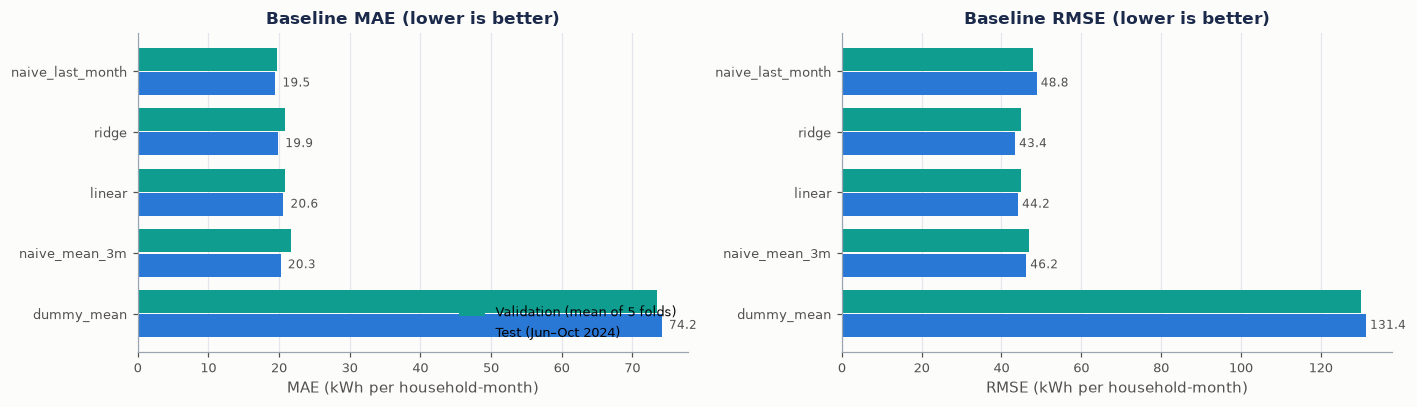

In [4]:
order = res.sort_values("cv_MAE").index
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
y = np.arange(len(order))
for a, metric, title in [(ax[0], "MAE", "MAE"), (ax[1], "RMSE", "RMSE")]:
    a.barh(y - 0.2, res.loc[order, f"cv_{metric}"], height=0.38, color=ps.TEAL, label="Validation (mean of 5 folds)")
    a.barh(y + 0.2, res.loc[order, f"test_{metric}"], height=0.38, color=ps.BLUE, label="Test (Jun–Oct 2024)")
    a.set_yticks(y); a.set_yticklabels(order); a.invert_yaxis(); a.grid(axis="y", visible=False)
    a.set(title=f"Baseline {title} (lower is better)", xlabel=f"{title} ({U} per household-month)")
    for i, v in enumerate(res.loc[order, f"test_{metric}"]):
        a.text(v + 1, i + 0.2, f"{v:.1f}", va="center", fontsize=8, color=ps.INK_2)
ax[0].legend(loc="lower right"); plt.tight_layout(); plt.show()

## 3. Validation stability across folds

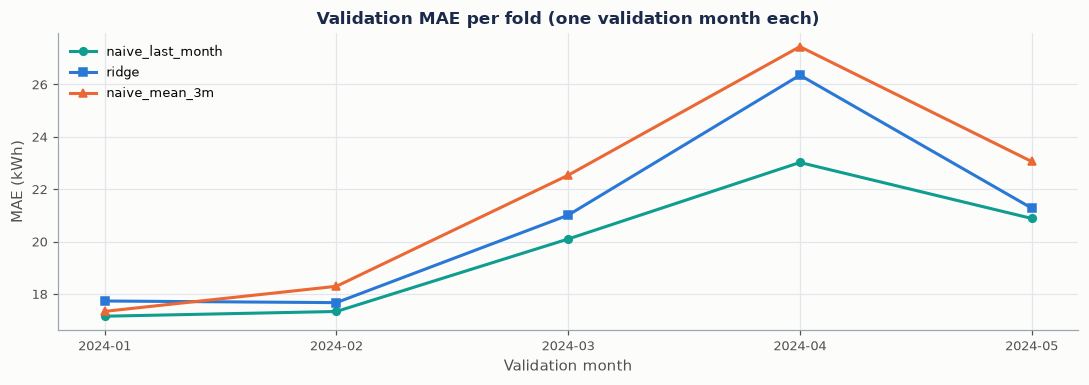

label,naive_last_month,ridge,linear,naive_mean_3m
validation_month,,,,
2024-01,17.15,17.73,17.53,17.33
2024-02,17.33,17.67,17.74,18.29
2024-03,20.10,21.01,20.95,22.53
2024-04,23.02,26.35,26.91,27.44
2024-05,20.88,21.28,21.42,23.05


In [5]:
cvs = pd.concat([load_cv("main", l).assign(label=l) for l in order if l != "dummy_mean"])
piv = cvs.pivot(index="validation_month", columns="label", values="val_MAE")[[l for l in order if l != "dummy_mean"]]
fig, ax = plt.subplots(figsize=(10, 3.6))
for l, c, mk in zip(["naive_last_month", "ridge", "naive_mean_3m"], ps.SERIES, ["o", "s", "^"]):
    ax.plot(piv.index, piv[l], marker=mk, color=c, label=l)
ax.set(title="Validation MAE per fold (one validation month each)", xlabel="Validation month", ylabel=f"MAE ({U})")
ax.legend(); plt.tight_layout(); plt.show()
piv.round(2)

## 4. What did Ridge learn?

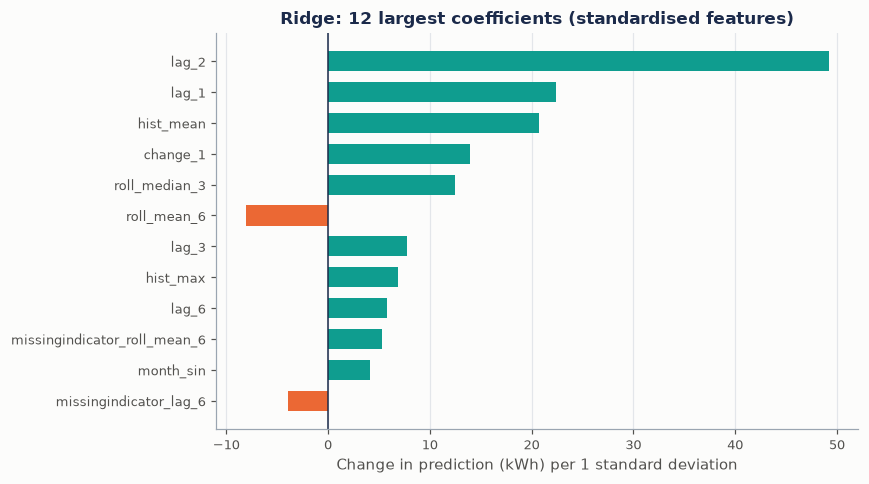

Intercept: 121.3 kWh


In [6]:
r = fitted["ridge"]
names = r.named_steps["preprocess"].get_feature_names_out()
coef = pd.Series(r.named_steps["model"].coef_, index=[n.replace("history__", "") for n in names])
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index[::-1], top.values[::-1], color=np.where(top.values[::-1] >= 0, ps.TEAL, ps.ORANGE), height=0.65)
ax.axvline(0, color=ps.NAVY, lw=1); ax.grid(axis="y", visible=False)
ax.set(title="Ridge: 12 largest coefficients (standardised features)", xlabel=f"Change in prediction ({U}) per 1 standard deviation")
plt.tight_layout(); plt.show()
print(f"Intercept: {r.named_steps['model'].intercept_:.1f} {U}")

**Observation.** Ridge relies on lag_2, lag_1, hist_mean, change_1 and roll_median_3. **Caution:** these features are
strongly correlated, and `change_1` is exactly `lag_1 − lag_2`, so the model can move weight between them freely. The
large lag_2 bar therefore does *not* mean the bill from two months ago matters more than last month's: combined with
change_1, the effective weights are roughly lag_1 ≈ 22 + 14 and lag_2 ≈ 49 − 14. Individual linear coefficients are not
reliable measures of importance when features are collinear — permutation importance is used for that in notebook 07.

## 5. Where do baselines fail? Actual vs predicted on the test period

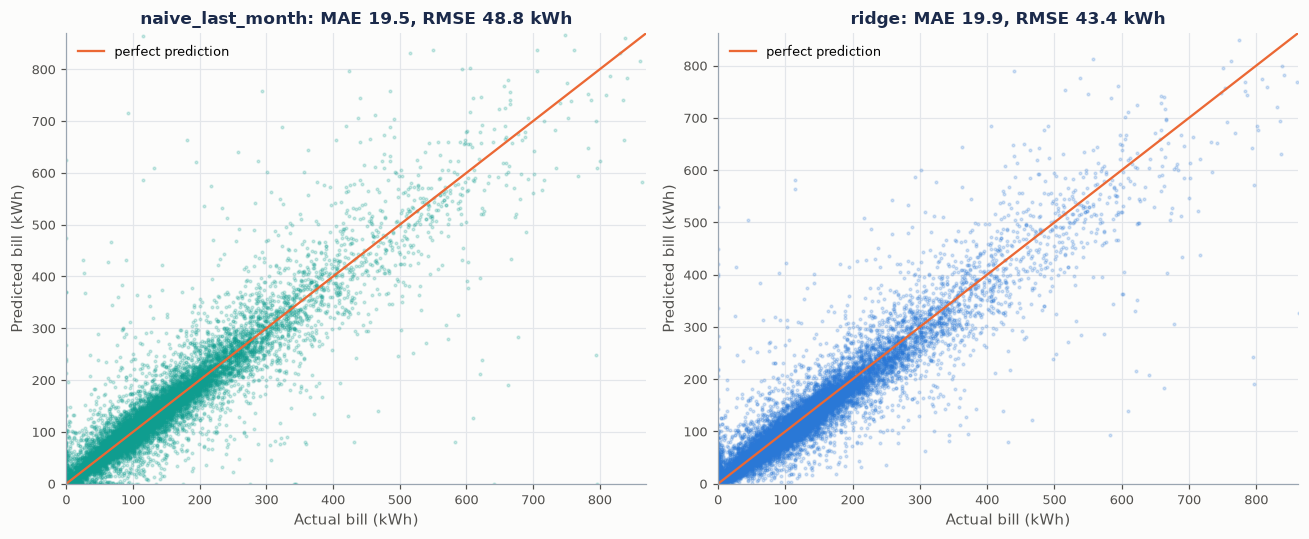

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, l, c in zip(ax, ["naive_last_month", "ridge"], [ps.TEAL, ps.BLUE]):
    p = load_test_predictions("main", l)
    lim = p[["actual", "predicted"]].quantile(.995).max()
    a.scatter(p.actual, p.predicted, s=3, alpha=0.2, color=c)
    a.plot([0, lim], [0, lim], color=ps.ORANGE, lw=1.5, label="perfect prediction")
    m_ = regression_metrics(p.actual, p.predicted)
    a.set(xlim=(0, lim), ylim=(0, lim), title=f"{l}: MAE {m_['MAE']:.1f}, RMSE {m_['RMSE']:.1f} {U}",
          xlabel=f"Actual bill ({U})", ylabel=f"Predicted bill ({U})"); a.legend(loc="upper left")
plt.tight_layout(); plt.show()

In [8]:
p = load_test_predictions("main", "naive_last_month").assign(err=lambda d: (d.predicted - d.actual).abs())
share = p.err.sort_values(ascending=False)
print(f"Naive baseline: the worst 5% of test rows account for {share.head(int(len(share)*0.05)).sum() / share.sum():.1%} of total absolute error")
print(f"Median absolute error: {p.err.median():.1f} {U} | 90th percentile: {p.err.quantile(.9):.1f} {U}")
per_month_metrics(p).set_index("month").round(2)

Naive baseline: the worst 5% of test rows account for 37.3% of total absolute error
Median absolute error: 9.0 kWh | 90th percentile: 43.0 kWh


,MAE,RMSE,R2,n
month,,,,
2024-06-01,23.15,50.35,0.86,4023.0
2024-07-01,18.69,42.73,0.87,4019.0
2024-08-01,18.20,37.99,0.92,4020.0
2024-09-01,18.45,54.63,0.84,4016.0
2024-10-01,18.96,56.03,0.82,4016.0


**Observation.** Errors are very unequal: the median absolute error of the naive forecast is only 9 kWh, but the 90th
percentile is 43 kWh and **the worst 5% of test rows cause 37% of the total absolute error**. These are the households
whose consumption jumped or dropped. That is where a learned model can add value — by recognising households that are
volatile (high roll_std_6, recent change, zeros/missing months) and weighting history differently for them.

June 2024 is the hardest test month for the naive forecast (MAE 23.2 kWh); the others are 18.2–19.0 kWh.

## 6. Summary

| Model | Validation MAE | Test MAE | Test RMSE | Test R² |
|---|---|---|---|---|
| Naive: last month | **19.69** | **19.49** | 48.84 | 0.861 |
| Ridge (alpha = 1000) | 20.81 | 19.89 | **43.41** | **0.890** |
| Linear Regression | 20.91 | 20.62 | 44.17 | 0.886 |
| Naive: mean of 3 months | 21.73 | 20.25 | 46.21 | 0.876 |
| DummyRegressor | 73.47 | 74.19 | 131.37 | −0.004 |

(kWh per household-month.) The simple persistence forecast is the strongest baseline by MAE; linear models are better
on large errors. Ensembles must beat both to be worthwhile.